# RNN and LSTM — PyTorch Practical Notebook

**Goal:** Train and compare a basic RNN and an LSTM on synthetic sequence classification.

Class 0 contains noise. Class 1 contains noise plus a strong spike at a random time step. This simple dataset demonstrates the workflow; it does not prove one architecture is always better.

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


## 2. Generate a dataset

In [2]:
def generate_data(n_samples=3000, seq_len=20):
    X = np.random.normal(0, 0.5, (n_samples, seq_len, 1)).astype(np.float32)
    y = np.zeros(n_samples, dtype=np.int64)
    for i in range(n_samples // 2):
        position = np.random.randint(seq_len)
        X[i, position, 0] += 3.0
        y[i] = 1
    order = np.random.permutation(n_samples)
    return X[order], y[order]

X, y = generate_data()
print("X shape:", X.shape, "| y shape:", y.shape)
print("Class counts:", np.bincount(y))

X shape: (3000, 20, 1) | y shape: (3000,)
Class counts: [1500 1500]


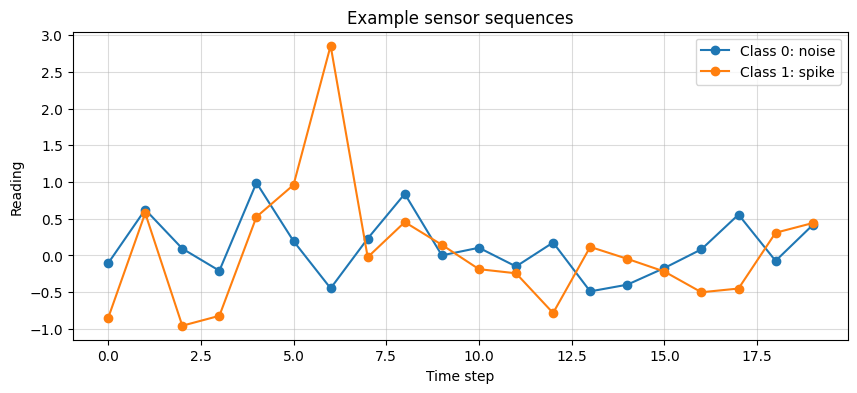

In [19]:
idx0 = np.where(y == 0)[0][0]
idx1 = np.where(y == 1)[0][0]
plt.figure(figsize=(10, 4))
plt.plot(X[idx0, :, 0], marker="o", label="Class 0: noise")
plt.plot(X[idx1, :, 0], marker="o", label="Class 1: spike")
plt.title("Example sensor sequences")
plt.xlabel("Time step")
plt.ylabel("Reading")
plt.legend()
plt.grid(alpha=0.45)
plt.show()

## 3. Split data and create DataLoaders

In [4]:
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

train_ds = TensorDataset(torch.tensor(X_train), torch.tensor(y_train))
test_ds = TensorDataset(torch.tensor(X_test), torch.tensor(y_test))
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (2400, 20, 1) Test: (600, 20, 1)


## 4. Build a reusable RNN/LSTM classifier

In [5]:
class SequenceClassifier(nn.Module):
    def __init__(self, cell_type="RNN", input_size=1, hidden_size=32, num_classes=2):
        super().__init__()
        if cell_type == "RNN":
            self.recurrent = nn.RNN(input_size, hidden_size, batch_first=True)
        elif cell_type == "LSTM":
            self.recurrent = nn.LSTM(input_size, hidden_size, batch_first=True)
        else:
            raise ValueError("cell_type must be RNN or LSTM")
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        if isinstance(self.recurrent, nn.LSTM):
            output, (hidden, cell) = self.recurrent(x)
        else:
            output, hidden = self.recurrent(x)
        return self.fc(hidden[-1])  # final layer's hidden state -> class logits

demo = SequenceClassifier("RNN").to(device)
print("Example output shape:", demo(torch.randn(8, 20, 1).to(device)).shape)

Example output shape: torch.Size([8, 2])


## 5. Train and evaluate

In [6]:
def train_and_evaluate(cell_type, epochs=8):
    model = SequenceClassifier(cell_type=cell_type).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    history = {"loss": [], "accuracy": []}

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            logits = model(inputs)
            loss = criterion(logits, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for inputs, labels in test_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                predictions = model(inputs).argmax(dim=1)
                correct += (predictions == labels).sum().item()
                total += labels.size(0)

        accuracy = correct / total
        history["loss"].append(avg_loss)
        history["accuracy"].append(accuracy)
        print(f"{cell_type} | epoch {epoch+1}/{epochs} | loss={avg_loss:.4f} | test accuracy={accuracy*100:.2f}%")
    return model, history

rnn_model, rnn_history = train_and_evaluate("RNN", epochs=8)

RNN | epoch 1/8 | loss=0.6970 | test accuracy=54.67%
RNN | epoch 2/8 | loss=0.6371 | test accuracy=74.00%
RNN | epoch 3/8 | loss=0.5466 | test accuracy=72.67%
RNN | epoch 4/8 | loss=0.5310 | test accuracy=77.83%
RNN | epoch 5/8 | loss=0.5195 | test accuracy=78.17%
RNN | epoch 6/8 | loss=0.5151 | test accuracy=79.33%
RNN | epoch 7/8 | loss=0.5068 | test accuracy=80.50%
RNN | epoch 8/8 | loss=0.4626 | test accuracy=81.67%


## 6. Train the LSTM

In [7]:
lstm_model, lstm_history = train_and_evaluate("LSTM", epochs=8)

LSTM | epoch 1/8 | loss=0.6921 | test accuracy=59.67%
LSTM | epoch 2/8 | loss=0.6347 | test accuracy=81.83%
LSTM | epoch 3/8 | loss=0.5064 | test accuracy=82.67%
LSTM | epoch 4/8 | loss=0.3990 | test accuracy=87.50%
LSTM | epoch 5/8 | loss=0.2922 | test accuracy=90.67%
LSTM | epoch 6/8 | loss=0.2084 | test accuracy=93.67%
LSTM | epoch 7/8 | loss=0.1761 | test accuracy=95.67%
LSTM | epoch 8/8 | loss=0.1312 | test accuracy=97.17%


## 7. Compare training loss

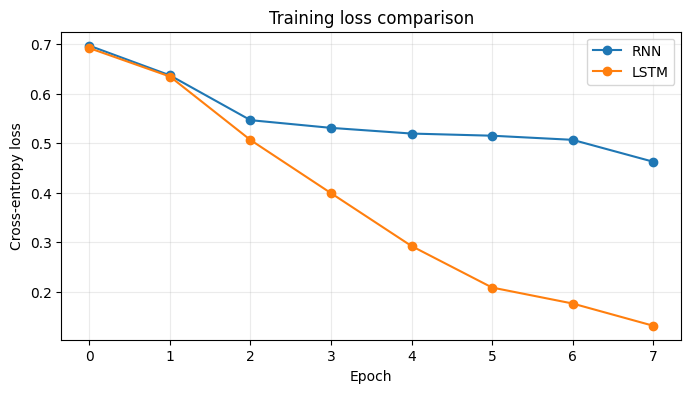

In [8]:
plt.figure(figsize=(8, 4))
plt.plot(rnn_history["loss"], marker="o", label="RNN")
plt.plot(lstm_history["loss"], marker="o", label="LSTM")
plt.title("Training loss comparison")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 8. Compare test metrics

In [9]:
comparison = pd.DataFrame({
    "Model": ["RNN", "LSTM"],
    "Final test accuracy (%)": [100*rnn_history["accuracy"][-1], 100*lstm_history["accuracy"][-1]],
    "Final training loss": [rnn_history["loss"][-1], lstm_history["loss"][-1]]
})
comparison.round(3)

,Model,Final test accuracy (%),Final training loss
0,RNN,81.667,0.463
1,LSTM,97.167,0.131


## 9. Inspect LSTM predictions

In [20]:
lstm_model.eval()
inputs, labels = next(iter(test_loader))
with torch.no_grad():
    logits = lstm_model(inputs.to(device))
    probabilities = torch.softmax(logits, dim=1)
    predictions = probabilities.argmax(dim=1).cpu().numpy()

pd.DataFrame({
    "actual_label": labels.numpy()[:12],
    "predicted_label": predictions[:12],
    "confidence": probabilities.max(dim=1).values.cpu().numpy().round(3)[:12]
})

,actual_label,predicted_label,confidence
0,1,1,0.956
1,1,1,0.969
2,1,1,0.949
3,1,1,0.967
4,1,1,0.989
5,1,1,0.989
6,0,0,0.972
7,0,0,0.981
8,0,0,0.957
9,1,1,0.984
